In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
from rdkit import Chem
from rdkit.Chem import PeriodicTable
from rdkit.Chem import AllChem
from rdkit.Chem import rdFingerprintGenerator as rdf
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import keras
from collections import defaultdict
from rdkit.Chem.rdPartialCharges import ComputeGasteigerCharges
from sklearn.model_selection import train_test_split
from rdkit.Chem import Descriptors
from rdkit.Chem import rdFreeSASA, rdqueries
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [2]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from xgboost.sklearn import XGBRegressor, XGBClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from lightgbm.sklearn import LGBMRegressor, LGBMRanker
from scipy.special import expit, logit
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import r2_score, matthews_corrcoef
import keras
import keras.layers as layers

In [3]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [4]:
df = pd.read_csv('PER_CARBON_FEATURIZED.csv', index_col=0)
df.drop(columns = 'substrate_smiles_mapped', inplace=True)

In [5]:
#df = df.drop(columns = ['hashed', 'new'])
df['SPLIT_1'].value_counts()

SPLIT_1
train    2945
val       727
new        54
Name: count, dtype: int64

In [6]:
important_feature_markers = ['lvl0', 'lvl1']
all_cols = list(df.columns)
for col1 in all_cols:
    for col2 in all_cols:
        for important_feature_marker in important_feature_markers:
            if important_feature_marker in col1 and important_feature_marker in col2:
                if f'{col1}_TIMES_{col2}' not in df.columns and f'{col2}_TIMES_{col1}' not in df.columns:
                    df[f'{col1}_TIMES_{col2}'] = df[col1]*df[col2]

/var/folders/xl/v8lcvy855_39wt1534xvs_hw0000gn/T/ipykernel_47345/2626786663.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'{col1}_TIMES_{col2}'] = df[col1]*df[col2]
/var/folders/xl/v8lcvy855_39wt1534xvs_hw0000gn/T/ipykernel_47345/2626786663.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f'{col1}_TIMES_{col2}'] = df[col1]*df[col2]
/var/folders/xl/v8lcvy855_39wt1534xvs_hw0000gn/T/ipykernel_47345/2626786663.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

In [7]:
df.fillna(-99999, inplace=True)

In [8]:
split_cols = [col for col in df.columns if 'SPLIT' in col]
X = df.drop(columns = split_cols + ['SUBSTRATE_reactivity', 'new'])
y = df.loc[:, 'SUBSTRATE_reactivity']


In [9]:
dummy_rf_binaryclassifier = RandomForestClassifier(random_state=42)
dummy_rf_multiclassifier = RandomForestClassifier(random_state=42)
dummy_rf_regressor = RandomForestRegressor(random_state=42)

In [10]:
def take_rows(X, order):
    return X.iloc[order] if hasattr(X, 'iloc') else X[order]

def get_col_names_map(X_train_, X_val_):
    X_val_ = X_val_.loc[:, X_train_.columns].copy()
                            
    original_feature_names = X_train_.columns.tolist()
    safe_names = [f'feature_{i}' for i in range(X_train_.shape[1])]
                            
    feature_name_map = dict(zip(safe_names, original_feature_names))
                            
    return safe_names, original_feature_names, feature_name_map
    

def evaluate_model(model_, type='binary', transform_data = False, dummy = False, nn = False):
    metric1 = []
    metric2 = []
    for i in range(5):
        splitno = i+1
        splitcol = f'SPLIT_{splitno}'
        X_train = X[df[splitcol] == 'train']
        y_train = pd.DataFrame(y[df[splitcol] == 'train'])
        

        X_val = X[df[splitcol] == 'val']
        y_val = pd.DataFrame(y[df[splitcol] == 'val'])

        myscaler= StandardScaler()
        X_train_scaled = pd.DataFrame(columns=X_train.columns, data=myscaler.fit_transform(X=X_train))
        X_val_scaled = pd.DataFrame(columns=X_val.columns, data=myscaler.transform(X=X_val))

        if type == 'linear':
            X_train_scaled.drop(columns = ['reaction_id'], inplace = True)
            X_val_scaled.drop(columns = ['reaction_id'], inplace = True)
            y_train = np.clip(y_train.values, 1e-5, 1 - 1e-5)
            y_val = np.clip(y_val.values, 1e-5, 1 - 1e-5)
            print(y_train)
            if transform_data:
                model = TransformedTargetRegressor(regressor=model_,func=logit, inverse_func=expit)
            else:
                model = model_

            safe_names, original_names, col_map = get_col_names_map(X_train_scaled, X_val_scaled)

            X_train_scaled.columns = safe_names
            X_val_scaled.columns = safe_names

            if nn:
                history = model_nn.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val), batch_size=20, epochs=200,)
            else:
                model.fit(X_train_scaled, y_train)
            preds = model.predict(X_val_scaled)
            preds_train = model.predict(X_train_scaled)
            
            mae = mean_absolute_error(preds, y_val)
            mse = mean_squared_error(preds, y_val)

            mae_train = mean_absolute_error(preds_train, y_train)

            r2 = r2_score(y_val, preds)

            r2_train = r2_score(y_train, preds_train)
            
            metric1.append([r2_train, r2])
            metric2.append([mae_train, mae])
            #return r2, mae
        
        elif type == 'binary':

            y_train['reaction_id'] = df.loc[y_train.index, 'reaction_id']
            y_val['reaction_id'] = df.loc[y_val.index, 'reaction_id']

            X_train_scaled.drop(columns = ['reaction_id'], inplace = True)
            X_val_scaled.drop(columns = ['reaction_id'], inplace = True)

            print(y_train)
            ###
            y_train['max_prob'] = y_train.groupby('reaction_id')['SUBSTRATE_reactivity'].transform('max')
            y_val['max_prob'] = y_val.groupby('reaction_id')['SUBSTRATE_reactivity'].transform('max')
            
            y_train_top1_bool = (y_train['max_prob'] == y_train['SUBSTRATE_reactivity'])
            y_val_top1_bool = (y_val['max_prob'] == y_val['SUBSTRATE_reactivity'])

            ###
            y_train_bool = y_train['SUBSTRATE_reactivity'] > 0
            y_val_bool = y_val['SUBSTRATE_reactivity'] > 0

            safe_names, original_names, col_map = get_col_names_map(X_train_scaled, X_val_scaled)
            
            X_train_scaled.columns = safe_names
            X_val_scaled.columns = safe_names

            model_.fit(X_train_scaled, y_train_bool)
            preds = model_.predict(X_val_scaled)
            f_score = f1_score(y_val_bool, preds)

            preds_train = model_.predict(X_train_scaled)
            f_score_train = f1_score(y_train_bool, preds_train)
            
            probs = model_.predict_proba(X_val_scaled)[:, 1]
            val_out = y_val.copy()
            val_out['reaction_id'] = df.loc[val_out.index, 'reaction_id']
            val_out['prob'] = probs

            probs_train = model_.predict_proba(X_train_scaled)[:, 1]
            train_out = y_train.copy()
            train_out['reaction_id'] = df.loc[train_out.index, 'reaction_id']
            train_out['prob'] = probs_train

            val_out['max_prob'] = val_out.groupby('reaction_id')['prob'].transform('max')
            val_out['pred_reacts'] = (val_out['max_prob'] == val_out['prob'])
            f_score_adj = f1_score(val_out['pred_reacts'], y_val_top1_bool)#val_out['SUBSTRATE_reactivity'])
            
            train_out['max_prob'] = train_out.groupby('reaction_id')['prob'].transform('max')
            train_out['pred_reacts'] = (train_out['max_prob'] == train_out['prob'])
            f_score_adj_train = f1_score(train_out['pred_reacts'], y_train_top1_bool)#train_out['SUBSTRATE_reactivity'])
            
            metric1.append([f_score_train, f_score])
            metric2.append([f_score_adj_train, f_score_adj])
            
            #return f_score, f_score_adj
        elif type == 'multiclass':
            X_train_scaled.drop(columns = ['reaction_id'], inplace = True)
            X_val_scaled.drop(columns = ['reaction_id'], inplace = True)

            safe_names, original_names, col_map = get_col_names_map(X_train_scaled, X_val_scaled)
            
            X_train_scaled.columns = safe_names
            X_val_scaled.columns = safe_names
            
            y_train = y_train['SUBSTRATE_reactivity'].apply(transform_regio_to_reactivity)
            y_val = y_val['SUBSTRATE_reactivity'].apply(transform_regio_to_reactivity)
            
            model_.fit(X_train_scaled, y_train.values)
            preds = model_.predict(X_val_scaled)
            preds_train = model_.predict(X_train_scaled)
            
            f_score = f1_score(y_val, preds, average='macro')
            f_score_train = f1_score(y_train, preds_train, average='macro')
            
            
            m_coof = matthews_corrcoef(y_val, preds)
            m_coof_train = matthews_corrcoef(y_train, preds_train)

            metric1.append([f_score_train, f_score])
            metric2.append([m_coof_train, m_coof])
            #return f_score, m_coof
        
        if dummy:
            return col_map

    return metric1, metric2


In [11]:
colmap = evaluate_model(dummy_rf_regressor, 'linear', dummy=True)

[[9.9999e-01]
 [1.0000e-05]
 [9.9999e-01]
 ...
 [9.9999e-01]
 [1.0000e-05]
 [1.0000e-05]]


/Users/romannemiatyi/anaconda3/lib/python3.13/site-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


In [12]:
df_importances = pd.DataFrame({'names' : dummy_rf_regressor.feature_names_in_, 'importances': dummy_rf_regressor.feature_importances_})
df_importances['names'] = df_importances['names'].map(colmap)
df_importances.sort_values('importances', inplace = True, ascending=False)
df_importances

,names,importances
75,SUBSTRATE_is_in_ring,0.042577
1,SUBSTRATE_free_vol_frac_1_above_6.0A,0.040438
59,SUBSTRATE_lvl2_Min_Partial_Charge,0.033921
411,SUBSTRATE_lvl0_Mean_Partial_Charge_TIMES_CATAL...,0.028793
73,SUBSTRATE_lvl4_Mean_Partial_Charge,0.028733
...,...,...
386,SUBSTRATE_lvl1_S_TIMES_CATALYST_lvl1_O,0.000000
388,SUBSTRATE_lvl1_S_TIMES_CATALYST_lvl1_P,0.000000
389,SUBSTRATE_lvl1_S_TIMES_CATALYST_lvl1_F,0.000000
390,SUBSTRATE_lvl1_S_TIMES_CATALYST_lvl1_Cl,0.000000


In [13]:
remaining_colnames = list(df_importances['names'].values[:50])


In [14]:
X = df.drop(columns = split_cols + ['SUBSTRATE_reactivity', 'new'])
y = df.loc[:, 'SUBSTRATE_reactivity']

In [15]:
def transform_regio_to_reactivity(regio_):
    if regio_ > 0.9:
        return 5 #'very high'
    elif regio_ > 0.7:
        return 4 #'high'
    elif regio_ > 0.5:
        return 3 #'medium'
    elif regio_  > 0.3:
        return 2 #'low'
    elif regio_ > 0.1:
        return 1 #'very low'
    else:
        return 0 #'none'

## Attempt no. 1: Regressors

In [16]:
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier

In [17]:
model_nn = keras.Sequential([
    layers.Dense(len(remaining_colnames)//2, activation='sigmoid', input_shape=[len(remaining_colnames)]),
    layers.BatchNormalization(),
    layers.Dropout(0.25),
    layers.Dense(len(remaining_colnames)//2, activation='relu'),
    layers.Dense(1)
])
model_nn.compile(
    optimizer='adam',
    loss='binary_crossentropy',
)

regressors = [
    DecisionTreeRegressor(min_samples_leaf = 2, random_state=42, splitter = 'random', min_samples_split = 3),
    RandomForestRegressor(min_samples_leaf = 2, random_state=42, min_samples_split = 3),
    XGBRegressor(max_depth = 10, learning_rate=0.03, subsample=0.8, random_state=42),
    
]

/Users/romannemiatyi/anaconda3/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [18]:
maes_all = []
r2s_all = []

for regressor in regressors:
    if regressor == model_nn:
        r2s, maes = evaluate_model(regressor, type = 'linear', nn=True)
    else:
        r2s, maes = evaluate_model(regressor, type = 'linear', transform_data = True)
    r2s_all.append(np.mean(r2s, axis = 0))
    maes_all.append(np.mean(maes, axis = 0))

[[9.9999e-01]
 [1.0000e-05]
 [9.9999e-01]
 ...
 [9.9999e-01]
 [1.0000e-05]
 [1.0000e-05]]
[[9.9999e-01]
 [1.0000e-05]
 [9.9999e-01]
 ...
 [1.0000e-05]
 [9.9999e-01]
 [1.0000e-05]]
[[9.9999e-01]
 [1.0000e-05]
 [9.9999e-01]
 ...
 [1.0000e-05]
 [9.9999e-01]
 [1.0000e-05]]
[[9.9999e-01]
 [1.0000e-05]
 [9.9999e-01]
 ...
 [1.0000e-05]
 [9.9999e-01]
 [1.0000e-05]]
[[1.0000e-05]
 [9.9999e-01]
 [1.0000e-05]
 ...
 [1.0000e-05]
 [9.9999e-01]
 [1.0000e-05]]
[[9.9999e-01]
 [1.0000e-05]
 [9.9999e-01]
 ...
 [9.9999e-01]
 [1.0000e-05]
 [1.0000e-05]]
[[9.9999e-01]
 [1.0000e-05]
 [9.9999e-01]
 ...
 [1.0000e-05]
 [9.9999e-01]
 [1.0000e-05]]
[[9.9999e-01]
 [1.0000e-05]
 [9.9999e-01]
 ...
 [1.0000e-05]
 [9.9999e-01]
 [1.0000e-05]]
[[9.9999e-01]
 [1.0000e-05]
 [9.9999e-01]
 ...
 [1.0000e-05]
 [9.9999e-01]
 [1.0000e-05]]
[[1.0000e-05]
 [9.9999e-01]
 [1.0000e-05]
 ...
 [1.0000e-05]
 [9.9999e-01]
 [1.0000e-05]]
[[9.9999e-01]
 [1.0000e-05]
 [9.9999e-01]
 ...
 [9.9999e-01]
 [1.0000e-05]
 [1.0000e-05]]
[[9.9999e-

In [19]:
maes_all = np.array(maes_all)
r2s_all = np.array(r2s_all)

In [20]:
import seaborn as sns
colors = sns.color_palette('muted')

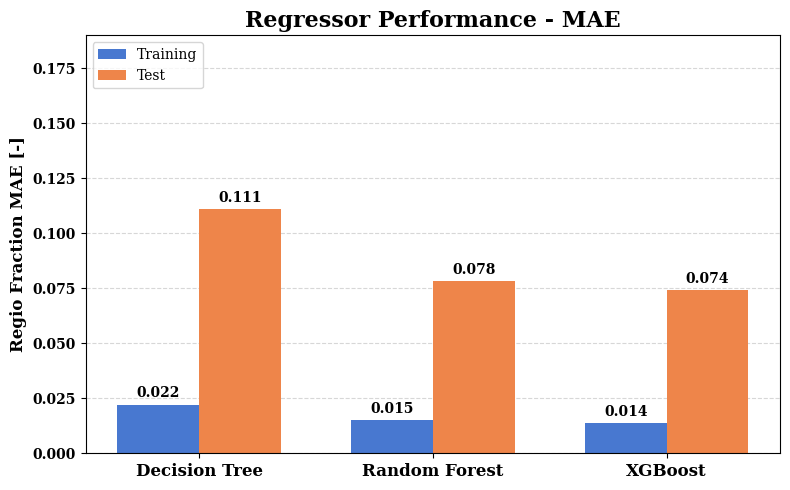

In [21]:
model_names = ['Decision Tree', 'Random Forest', 'XGBoost']
mae_train = maes_all[:, 0].copy()
mae_val = maes_all[:, 1].copy()

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars_train = ax.bar(
    x - width / 2, mae_train, width,
    label='Training', color = colors[0])

bars_val = ax.bar(
    x + width / 2, mae_val, width,
    label='Test', color = colors[1]
)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.5, ls='--')

for bars in (bars_train, bars_val):
    ax.bar_label(bars, fmt='%.3f', padding=3, fontfamily='serif', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize =12)

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontfamily('serif')
    label.set_fontweight('bold')

ax.set_ylabel('Regio Fraction MAE [-]', fontfamily='serif', fontweight='semibold', fontsize=12)
ax.set_title( 'Regressor Performance - MAE', fontfamily='serif', fontweight='bold', fontsize=16)

ax.legend(prop={'family': 'serif'}, loc = 'upper left')
ax.set_ylim(0, 0.19)
ax.margins(y=0.15)
plt.tight_layout()
plt.savefig('regressor_performance_mae.png', dpi=300, bbox_inches='tight')

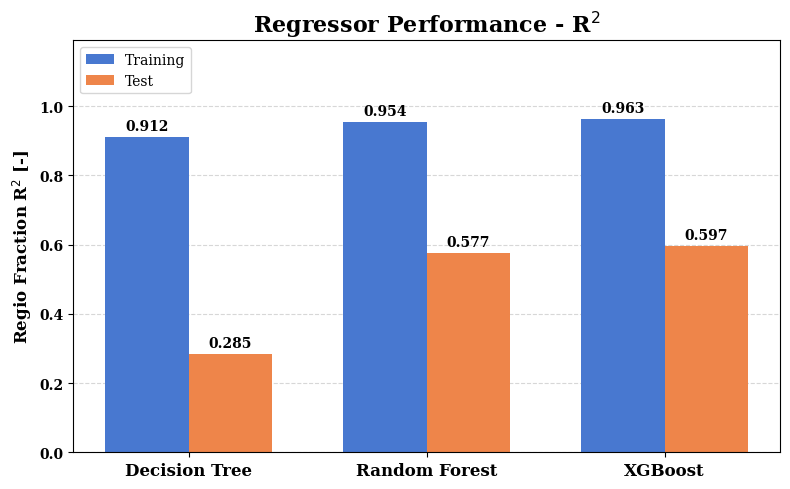

In [22]:
r2_train = r2s_all[:, 0].copy()
r2_val = r2s_all[:, 1].copy()

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars_train = ax.bar(
    x - width / 2, r2_train, width,
    label='Training', color = colors[0])
bars_val = ax.bar(
    x + width / 2, r2_val, width,
    label='Test', color = colors[1]
)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.5, ls='--')

for bars in (bars_train, bars_val):
    ax.bar_label(
        bars, fmt='%.3f', padding=3,
        fontfamily='serif', fontweight='bold'
    )

ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=12)

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontfamily('serif')
    label.set_fontweight('bold')

ax.set_ylabel('Regio Fraction R$^2$ [-]', fontfamily='serif', fontweight='semibold', fontsize=12)
ax.set_title( 'Regressor Performance - R$^2$', fontfamily='serif', fontweight='bold', fontsize=16)

ax.legend(prop={'family': 'serif'}, loc = 'upper left')
ax.set_ylim(0, 1.19)
ax.margins(y=0.15)
plt.tight_layout()
plt.savefig('regressor_performance_r2.png', dpi=300, bbox_inches='tight')

In [23]:
X = df.drop(columns = split_cols + ['SUBSTRATE_reactivity', 'new'])
colmap = evaluate_model(dummy_rf_binaryclassifier, 'binary', dummy=True)

      SUBSTRATE_reactivity  reaction_id
0                      1.0            0
6                      0.0            2
7                      1.0            2
8                      0.0            2
11                     0.0            4
...                    ...          ...
3719                   1.0          635
3720                   0.0          635
3721                   1.0          636
3722                   0.0          636
3723                   0.0          636

[2945 rows x 2 columns]


In [24]:
df_importances = pd.DataFrame({'names' : dummy_rf_binaryclassifier.feature_names_in_, 'importances': dummy_rf_binaryclassifier.feature_importances_})
df_importances['names'] = df_importances['names'].map(colmap)
df_importances.sort_values('importances', inplace = True, ascending=False)
df_importances

,names,importances
1,SUBSTRATE_free_vol_frac_1_above_6.0A,0.020315
50,SUBSTRATE_lvl0_Mean_Partial_Charge,0.015282
59,SUBSTRATE_lvl2_Min_Partial_Charge,0.013487
410,SUBSTRATE_lvl0_Mean_Partial_Charge_TIMES_SUBST...,0.013063
409,SUBSTRATE_lvl0_Mean_Partial_Charge_TIMES_SUBST...,0.012999
...,...,...
90,SOLVENT_COC(C)(C)C,0.000000
92,SOLVENT_C1CCOC1,0.000000
365,SUBSTRATE_lvl1_P_TIMES_SUBSTRATE_lvl1_Max_Part...,0.000000
367,SUBSTRATE_lvl1_P_TIMES_SUBSTRATE_lvl1_Mean_Hyb...,0.000000


In [25]:
remaining_colnames_binary = list(df_importances['names'].values[:50])
X = X[remaining_colnames_binary + ['reaction_id']]

In [26]:
binary_classifiers = [
    DecisionTreeClassifier(min_samples_leaf = 2, random_state=42, splitter = 'best', min_samples_split = 3, class_weight = 'balanced', min_weight_fraction_leaf = 0.001),
    RandomForestClassifier(200, max_depth = 10, random_state=42, min_samples_leaf = 3,  class_weight = 'balanced', bootstrap = True, min_samples_split = 3, max_features = 0.8),
    XGBClassifier(max_depth = 6, learning_rate=0.03, subsample=0.8, random_state=42,)
]

f1s_all = []
f1s_adj_all = []

for classifier in binary_classifiers:
    f1, f1_adj = evaluate_model(classifier, type = 'binary')
    f1s_all.append(np.mean(f1, axis = 0))
    f1s_adj_all.append(np.mean(f1_adj, axis = 0))

      SUBSTRATE_reactivity  reaction_id
0                      1.0            0
6                      0.0            2
7                      1.0            2
8                      0.0            2
11                     0.0            4
...                    ...          ...
3719                   1.0          635
3720                   0.0          635
3721                   1.0          636
3722                   0.0          636
3723                   0.0          636

[2945 rows x 2 columns]
      SUBSTRATE_reactivity  reaction_id
0                      1.0            0
1                      0.0            1
2                      1.0            1
3                      0.0            1
4                      0.0            1
...                    ...          ...
3721                   1.0          636
3722                   0.0          636
3723                   0.0          636
3724                   1.0          637
3725                   0.0          637

[2932 rows x 2

In [27]:
f1s_all = np.array(f1s_all)
f1s_adj_all = np.array(f1s_adj_all)

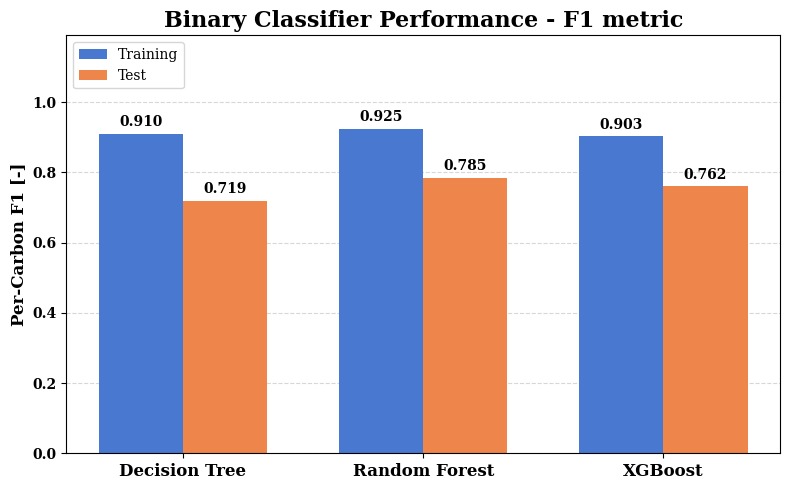

In [28]:
model_names = ['Decision Tree', 'Random Forest', 'XGBoost']
mae_train = f1s_all[:, 0].copy()
mae_val = f1s_all[:, 1].copy()

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars_train = ax.bar(
    x - width / 2, mae_train, width,
    label='Training', color = colors[0])
bars_val = ax.bar(
    x + width / 2, mae_val, width,
    label='Test', color = colors[1]
)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.5, ls='--')


for bars in (bars_train, bars_val):
    ax.bar_label(bars, fmt='%.3f', padding=3, fontfamily='serif', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=12)

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontfamily('serif')
    label.set_fontweight('bold')

ax.set_ylabel('Per-Carbon F1 [-]', fontfamily='serif', fontweight='semibold', fontsize=12)
ax.set_title('Binary Classifier Performance - F1 metric', fontfamily='serif', fontweight='bold', fontsize=16)

ax.legend(prop={'family': 'serif'}, loc = 'upper left')
ax.set_ylim(0, 1.19)
ax.margins(y=0.15)
plt.tight_layout()
plt.savefig('binary_classifiers_f1.png', dpi=300, bbox_inches='tight')

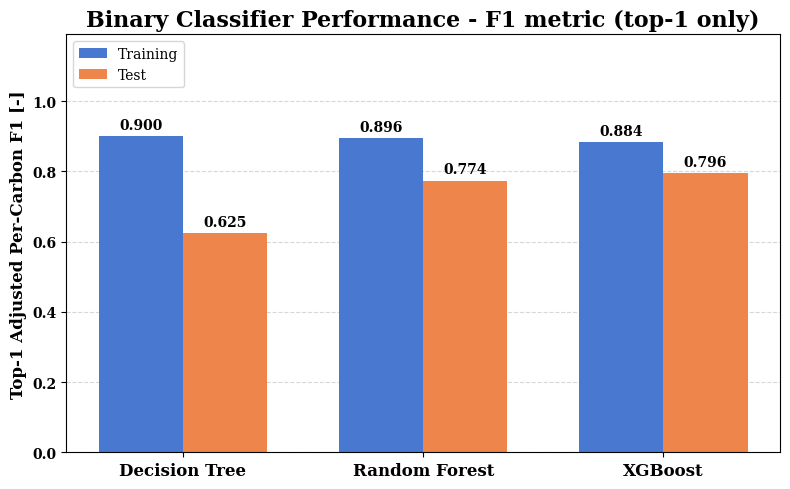

In [29]:
mae_train = f1s_adj_all[:, 0].copy()
mae_val = f1s_adj_all[:, 1].copy()

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars_train = ax.bar(
    x - width / 2, mae_train, width,
    label='Training', color = colors[0])
bars_val = ax.bar(
    x + width / 2, mae_val, width,
    label='Test', color = colors[1]
)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.5, ls='--')

for bars in (bars_train, bars_val):
    ax.bar_label(bars, fmt='%.3f', padding=3, fontfamily='serif', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=12)

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontfamily('serif')
    label.set_fontweight('bold')

ax.set_ylabel('Top-1 Adjusted Per-Carbon F1 [-]', fontfamily='serif', fontweight='semibold', fontsize=12)
ax.set_title('Binary Classifier Performance - F1 metric (top-1 only)', fontfamily='serif', fontweight='bold', fontsize=16)

ax.legend(prop={'family': 'serif'}, loc = 'upper left')
ax.set_ylim(0, 1.19)
ax.margins(y=0.15)
plt.tight_layout()
plt.savefig('binary_classifiers_f1_top1.png', dpi=300, bbox_inches='tight')

In [30]:
X = df.drop(columns = split_cols + ['SUBSTRATE_reactivity', 'new'])
y = df.loc[:, 'SUBSTRATE_reactivity']
colmap = evaluate_model(dummy_rf_multiclassifier, 'multiclass', dummy=True)

In [31]:
df_importances = pd.DataFrame({'names' : dummy_rf_multiclassifier.feature_names_in_, 'importances': dummy_rf_multiclassifier.feature_importances_})
df_importances['names'] = df_importances['names'].map(colmap)
df_importances.sort_values('importances', inplace = True, ascending=False)
df_importances

,names,importances
59,SUBSTRATE_lvl2_Min_Partial_Charge,0.015626
1,SUBSTRATE_free_vol_frac_1_above_6.0A,0.015149
410,SUBSTRATE_lvl0_Mean_Partial_Charge_TIMES_SUBST...,0.013355
58,SUBSTRATE_lvl2_Max_Partial_Charge,0.012877
310,SUBSTRATE_lvl1_C_TIMES_SUBSTRATE_lvl1_Mean_Par...,0.012318
...,...,...
389,SUBSTRATE_lvl1_S_TIMES_CATALYST_lvl1_F,0.000000
387,SUBSTRATE_lvl1_S_TIMES_CATALYST_lvl1_N,0.000000
287,SUBSTRATE_lvl1_H_TIMES_SUBSTRATE_lvl1_P,0.000000
289,SUBSTRATE_lvl1_H_TIMES_SUBSTRATE_lvl1_Si,0.000000


In [32]:
X = df.drop(columns = split_cols + ['SUBSTRATE_reactivity', 'new'])
remaining_colnames = list(df_importances['names'].values[:50])
X = X[remaining_colnames + ['reaction_id']]

In [33]:
classifiers = [
    DecisionTreeClassifier(min_samples_leaf=2, random_state=42, splitter='best', min_samples_split=3, class_weight='balanced', min_weight_fraction_leaf=0.001),
    RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, min_samples_leaf=3, class_weight='balanced', bootstrap=True),
    XGBClassifier(max_depth=6, learning_rate=0.03, subsample=0.8, random_state=42)
]

f1s_mv_all = []
mccs = []

for classifier in classifiers:
    f1_mv, mcc = evaluate_model(classifier, type = 'multiclass')
    f1s_mv_all.append(np.mean(f1_mv, axis = 0))
    mccs.append(np.mean(mcc, axis = 0))

In [34]:
f1s_mv_all = np.array(f1s_mv_all)
mccs = np.array(mccs)

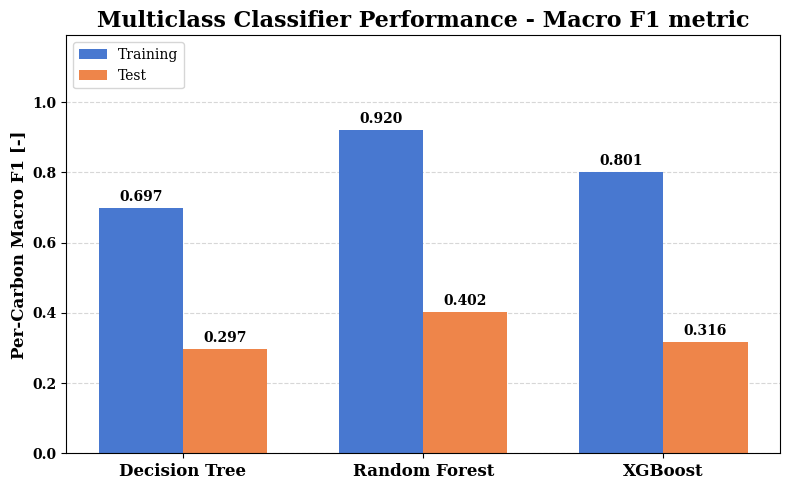

In [35]:
model_names = ['Decision Tree', 'Random Forest', 'XGBoost']
mae_train = f1s_mv_all[:, 0].copy()
mae_val = f1s_mv_all[:, 1].copy()

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars_train = ax.bar(
    x - width / 2, mae_train, width,
    label='Training', color = colors[0])
bars_val = ax.bar(
    x + width / 2, mae_val, width,
    label='Test', color = colors[1]
)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.5, ls='--')

for bars in (bars_train, bars_val):
    ax.bar_label(bars, fmt='%.3f', padding=3, fontfamily='serif', fontweight='bold')


ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=12)

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontfamily('serif')
    label.set_fontweight('bold')

ax.set_ylabel('Per-Carbon Macro F1 [-]', fontfamily='serif', fontweight='semibold', fontsize=12)
ax.set_title('Multiclass Classifier Performance - Macro F1 metric', fontfamily='serif', fontweight='bold', fontsize=16)

ax.legend(prop={'family': 'serif'}, loc = 'upper left')

ax.margins(y=0.15)
plt.tight_layout()
ax.set_ylim(0, 1.19)
plt.savefig('multiclass_classifiers_f1.png', dpi=300, bbox_inches='tight')

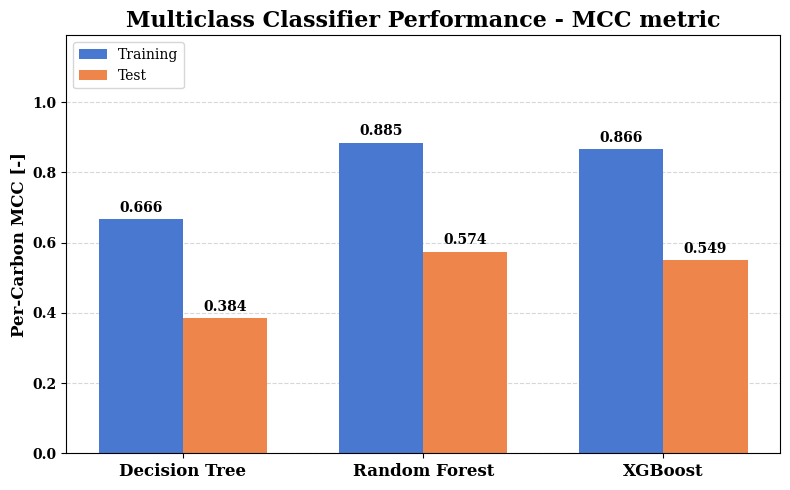

In [36]:
mae_train = mccs[:, 0].copy()
mae_val = mccs[:, 1].copy()

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars_train = ax.bar(
    x - width / 2, mae_train, width,
    label='Training', color = colors[0])
bars_val = ax.bar(
    x + width / 2, mae_val, width,
    label='Test', color = colors[1]
)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.5, ls='--')

for bars in (bars_train, bars_val):
    ax.bar_label(bars, fmt='%.3f', padding=3, fontfamily='serif', fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize = 12)

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontfamily('serif')
    label.set_fontweight('bold')

ax.set_ylabel('Per-Carbon MCC [-]', fontfamily='serif', fontweight='semibold', fontsize=12)
ax.set_title('Multiclass Classifier Performance - MCC metric', fontfamily='serif', fontweight='bold', fontsize=16)

ax.legend(prop={'family': 'serif'}, loc = 'upper left')

ax.margins(y=0.15)
plt.tight_layout()
ax.set_ylim(0, 1.19)
plt.savefig('multiclass_classifiers_mcc.png', dpi=300, bbox_inches='tight')

In [37]:
len(remaining_colnames)

50

In [38]:
features = remaining_colnames_binary

split_cols = [col for col in df.columns if 'SPLIT' in col]

X = df.loc[df['new'] == False, features]
X_new = df.loc[df['new'] == True, features]
y = df.loc[df['new'] == False, 'SUBSTRATE_reactivity'] > 0
y_new = df.loc[df['new'] == True, 'SUBSTRATE_reactivity'] > 0

In [39]:
model = binary_classifiers[1]

data_new = df[df['new'] == True].copy()

for col in data_new.columns:
    if 'SPLIT_' in col:
        data_new.drop(columns = col, inplace = True)

In [40]:
myscaler = StandardScaler()
myscaler.fit_transform(X)
myscaler.transform(X_new)

safe_names, original_names, col_map = get_col_names_map(X, X_new)
X.columns = safe_names
X_new.columns = safe_names
model.fit(X, y)
y_pred = model.predict(X_new)



In [41]:
print(f1_score(y_new, y_pred))

0.2857142857142857
